In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler 
from sklearn.decomposition import PCA

In [3]:
df = pd.read_csv('C:/Users/cesar/Desktop/Practica/Dia_8/dataset_pca_practica.csv')

In [4]:
df.head()

,ID_Cliente,Edad,Experiencia_Años,Ingreso_Anual,Monto_Credito,Puntaje_Credito,Gasto_Mensual,Deuda_Actual,Tipo_Vivienda,Nivel_Riesgo
0,CLI-1000,74.5,35.8,169208.21,63825.88,688,9619.36,23918.01,Propia,Medio
1,CLI-1001,49.5,19.8,103494.92,32069.48,614,6132.74,11354.35,Hipotecada,Medio
2,CLI-1002,52.9,20.7,106092.44,32975.54,612,5684.23,14398.11,Alquilada,Medio
3,CLI-1003,48.0,22.2,112403.66,39896.44,590,6774.62,17289.01,Alquilada,Medio
4,CLI-1004,49.8,23.7,110023.77,31162.88,585,6758.52,11746.36,Hipotecada,Medio


## Preparacion de dataframe para matriz de correlacion

In [10]:
df = df.drop(["ID_Cliente"], axis=1)

## One hot encodig

In [11]:
encoded_df = pd.get_dummies(df, columns=["Nivel_Riesgo"])

In [12]:
encoded_df = pd.get_dummies(encoded_df, columns=['Tipo_Vivienda'])

In [ ]:
# NOTA: Para la etapa de EDA, conviene utlizar el dummy, para preparar datos para entrenar modelos, conviene utilizar OneHotEncoder.

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoder.set_output(transform="pandas") # Se le indica que la salida sea directamente un DataFrame.

# Ajustar y transformar:
encoded_df = encoder.fit_transform(df_data[["categoric_column"]])

"""
Una matriz dispersa solo guarda en la memoria las posiciones donde hay un 1, ignorando los miles o millones de 0, entonces:
Cuando utilizar sparse_output=True? --> Cuando se manejan volúmenes masivos de datos (por ejemplo, millones de filas con cientos de categorías
o texto masivo) donde la memoria RAM de la computadora corre el riesgo de agotarse.

Si el modelo encuentra en el set de testing, una categoria que no "habia visto" antes  en el set de entrenamiento, simplemente la ignora
(crea una fila con puros ceros para esas columnas de One-Hot) en lugar de arruinar el pipeline o predicción.
"""

## Matriz de correlacion de Pearson

<Axes: >

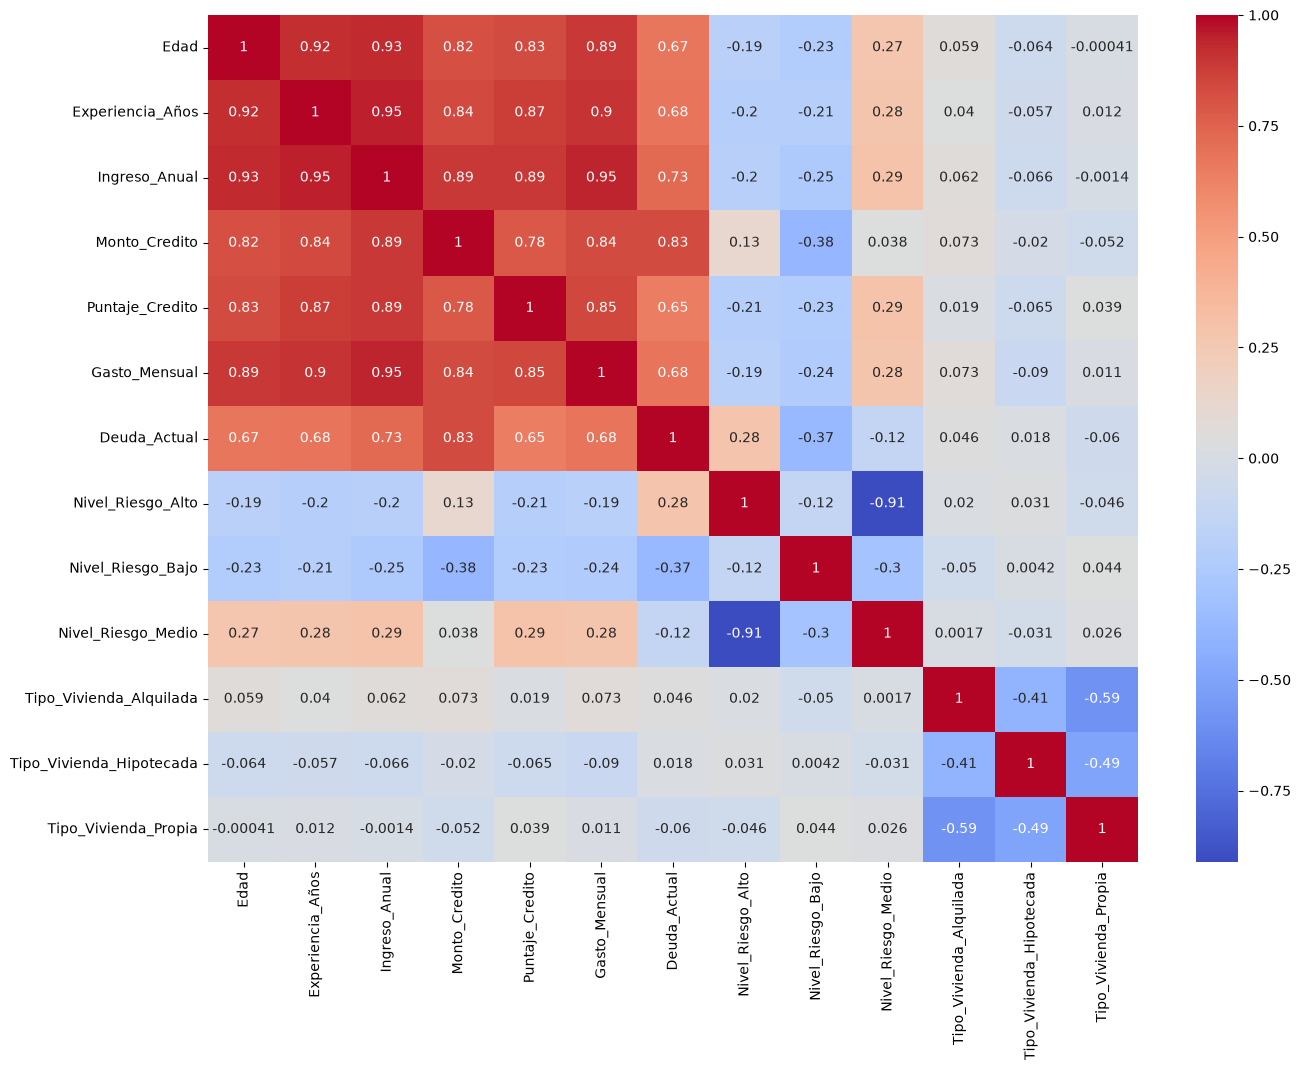

In [13]:
matriz_correlacion = encoded_df.corr(method='pearson')
plt.figure(figsize=(15, 11))
sns.heatmap(matriz_correlacion, annot=True, cmap="coolwarm")

## Estandarizacion

In [15]:
scaler = StandardScaler()
standardized_matrix = scaler.fit_transform(encoded_df) # .fit_transform devuelve una matriz numérica de NumPy.

## PCA

In [17]:
pca = PCA(n_components=len(encoded_df.columns)) # "Calcula tantas componentes principales como columnas tenga tenga el DataFrame". Se calculan todas para poder evaluar el 100% de la varianza antes de decidir cuántas eliminar.
PCA_matrix = pca.fit_transform(standardized_matrix) # Matriz de dos dimensiones.

componentes_cols = [f'PC{i+1}' for i in range(len(encoded_df.columns))] 
df_pca = pd.DataFrame(PCA_matrix, columns=componentes_cols) # Guarda las componentes en un nuevo DataFrame.

varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

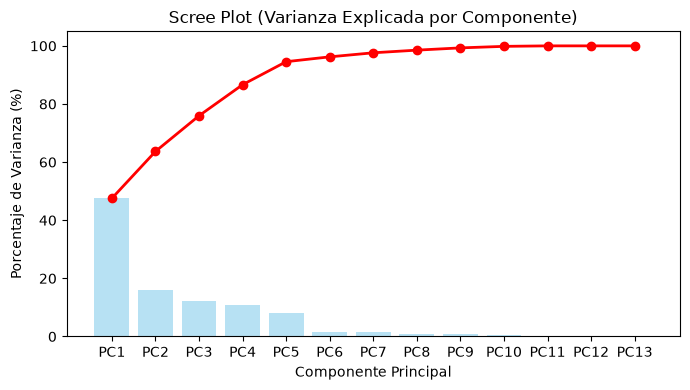

In [22]:
plt.figure(figsize=(7, 4))
plt.title("Scree Plot (Varianza Explicada por Componente)")
plt.xlabel("Componente Principal")
plt.ylabel("Porcentaje de Varianza (%)")

plt.bar(componentes_cols, varianza_explicada * 100, alpha=0.6, color='skyblue', label='Varianza Individual')
plt.plot(componentes_cols, varianza_acumulada * 100, color='red', marker='o', linewidth=2, label='Varianza Acumulada')

plt.tight_layout()
plt.show()

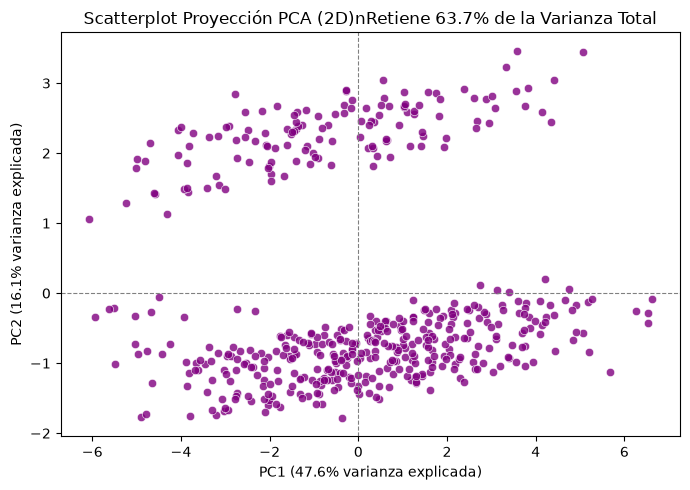

In [23]:
plt.figure(figsize=(7, 5))
plt.title(f"Scatterplot Proyección PCA (2D)nRetiene {varianza_acumulada[1]*100:.1f}% de la Varianza Total")
plt.xlabel(f"PC1 ({varianza_explicada[0]*100:.1f}% varianza explicada)")
plt.ylabel(f"PC2 ({varianza_explicada[1]*100:.1f}% varianza explicada)")
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)

sns.scatterplot(data=df_pca, x='PC1', y='PC2', alpha=0.8, color='purple')

plt.tight_layout()
plt.show()